# Overlap of DEGs
I'm interested if there are shared DEGs among oysters that experience stressors at different ages (or if the DEGs I identify are purely due to differences in the age of the oysters)

## 0. load libraries

In [3]:
library(tidyverse)

# for venn diagrams/upset plots
library(ggvenn)
library(UpSetR)

# for visualization
#library(virdis)
library(RColorBrewer)

## 1. read csvs

### all genes
from [DESeq](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/compare_phases/deseq_comparePhase.ipynb)

for all of these, the "baseline" is the phase 1 oyster 

In [4]:
# CONTROL
cc_c <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cc_c.csv') %>%
rename('Gene' = X)

# HYPOXIC
ch_h <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/ch_h.csv') %>%
rename('Gene' = X)

# WARM
cw_w <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cw_w.csv') %>%
rename('Gene' = X)

cb_b <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cb_b.csv') %>%
rename('Gene' = X)
head(cb_b)

,Gene,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,2085.5663,-0.04563055,0.1833458,0.748297600,0.91452790
2,LOC144621269,2556.3795,-0.06500174,0.3789901,0.440654021,0.74859859
3,LOC111120925,142.0638,0.91139689,1.5574705,0.002487047,0.04746309
4,LOC144621283,888.4466,0.15319682,0.1830420,0.281962171,0.62166646
5,LOC144621276,12535.4692,0.41424753,0.1807497,0.003627159,0.05943955
6,LOC111115920,180.4656,-0.26129043,0.2759291,0.080019987,0.33005602


In [5]:
df_list <- list(control = cc_c, 
                warm = cw_w, 
                hypoxic = ch_h, 
                both = cb_b)
names(df_list)

[1] "control" "warm"    "hypoxic" "both"

### DEGs

In [6]:
deg.list <- lapply(df_list, function(df) filter(df, padj < 0.05 & abs(log2FoldChange > 1)))

## 2. venn diagram

Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


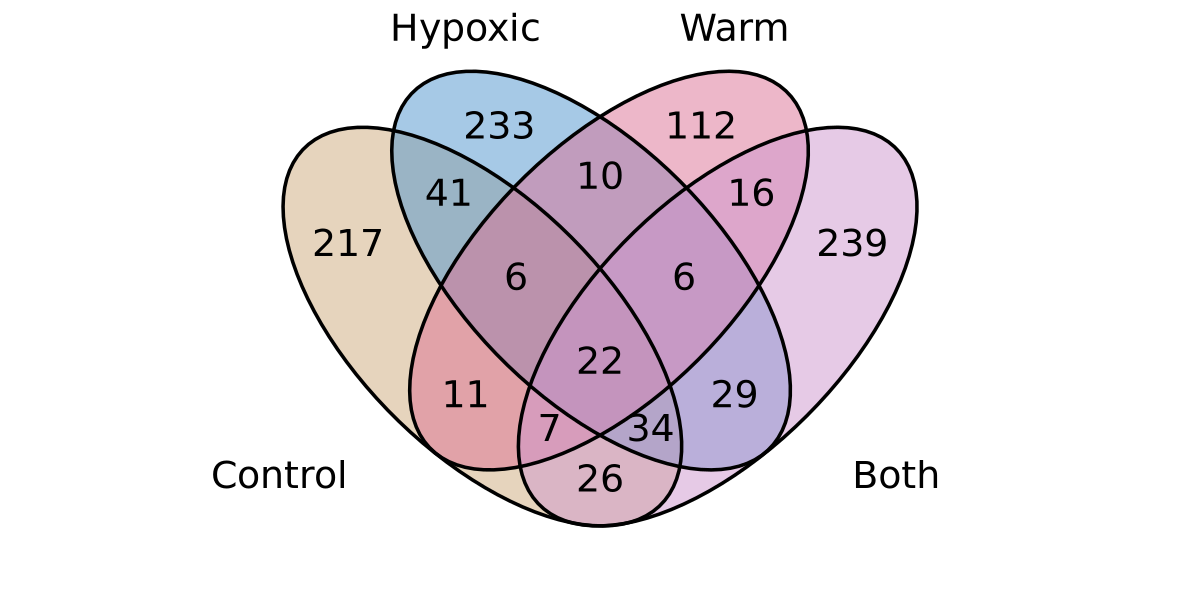

In [9]:
options(repr.plot.width=10, repr.plot.height=5)

# make list of dfs
x = list('Control' = deg.list$control$Gene,
         'Hypoxic' = deg.list$hypoxic$Gene,
        'Warm' = deg.list$warm$Gene,
        'Both' = deg.list$both$Gene)

ggvenn(x,
       fill_color = c("burlywood3", "steelblue3", "palevioletred", "plum3"),
       text_size = 8,
       set_name_size = 8,
       show_percentage = FALSE
) +
  coord_fixed(clip = "off") +
  theme(plot.margin = margin(t = 10, r = 10, b = 30, l = 10, unit = "pt"))

all DEGs are due to oysters experiencing the same treatment/stressor one time but at different timepoints (phase 1 or phase 2)

I think any DEG that overlaps with those from C vs. CC are safe to say that they're due to the age of the oyster - so I think I should remove those, and then look at the overlap of hypoxic, warm, and both to see if there's common differences between oysters (but similarities would only tell me that there might be a "general" response to stress that is shared across a phase (but you wouldn't know the direction just from this plot))

#### remove control DEGs from environmental response
removing DEGs identified in the stress conditions that have overlap with DEGs from C vs. CC, as those are likely due to differences in age rather than experiencing environments at different ages

In [15]:
## HYPOXIC
hyp.subset <- deg.list$hypoxic[!deg.list$hypoxic$Gene %in% deg.list$control$Gene,]

hyp.before <- dim(deg.list$hypoxic)[1]
hyp.after <- dim(hyp.subset)[1]

paste0('Percent of DEGs kept after filter: ', hyp.after/hyp.before * 100, '%')

[1] "Percent of DEGs kept after filter: 72.9658792650919%"

In [16]:
## WARM
warm.subset <- deg.list$warm[!deg.list$warm$Gene %in% deg.list$control$Gene,]

warm.before <- dim(deg.list$warm)[1]
warm.after <- dim(warm.subset)[1]

paste0('Percent of DEGs kept after filter: ', warm.after/warm.before * 100, '%')

[1] "Percent of DEGs kept after filter: 75.7894736842105%"

In [17]:
## BOTH
both.subset <- deg.list$both[!deg.list$both$Gene %in% deg.list$control$Gene,]

both.before <- dim(deg.list$both)[1]
both.after <- dim(both.subset)[1]

paste0('Percent of DEGs kept after filter: ', both.after/both.before * 100, '%')

[1] "Percent of DEGs kept after filter: 76.5171503957784%"

so for all other treatments, about 25% of their identified DEGs were due purely to differences in age

Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


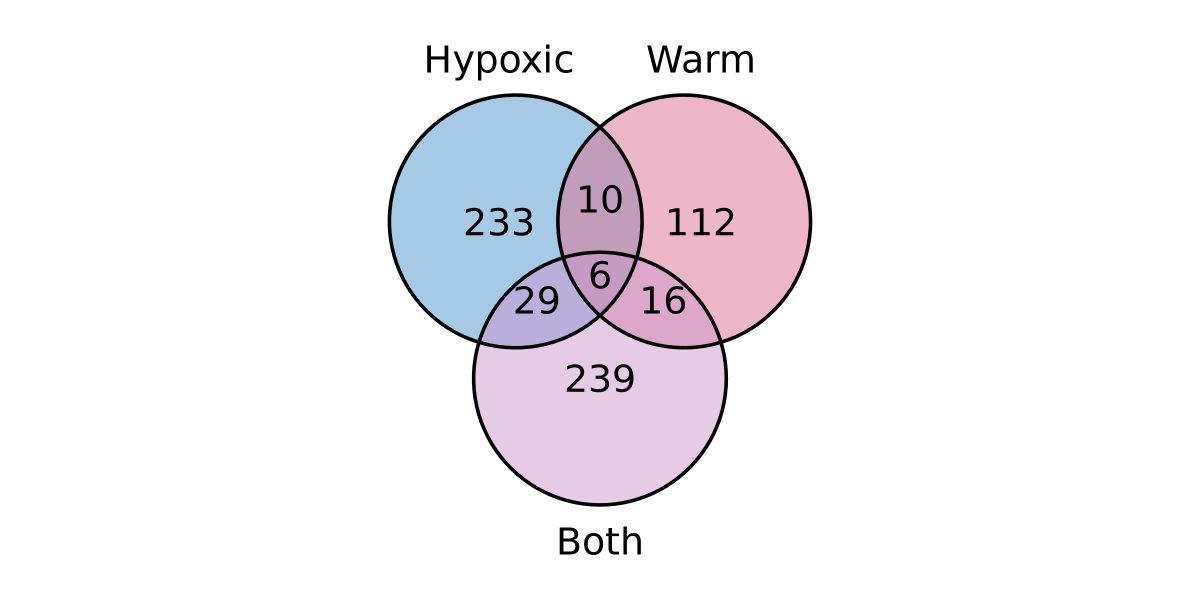

In [30]:
options(repr.plot.width=10, repr.plot.height=5)

# make list of dfs
x = list('Hypoxic' = hyp.subset$Gene,
        'Warm' = warm.subset$Gene,
        'Both' = both.subset$Gene)

ggvenn(x,
       fill_color = c("steelblue3", "palevioletred", "plum3"),
       text_size = 8,
       set_name_size = 8,
       show_percentage = FALSE
) +
  coord_fixed(clip = "off") +
  theme(plot.margin = margin(t = 30, r = 10, b = 30, l = 10, unit = "pt"))

so these are DEGs purely due to different stress responses at different ages. overlap indicates shared responses to stress - hopefully at the same age? but can't see that here

# Overlap of phase 1 and 2 results
similar to the above analysis, but instead of comparing phase 1 and 2 directly, I'm going to compare results from phase 1 to results from phase 2 (e.g., CC vs. CW in phase 2 and C vs. W in phase 1)

## 1. read csvs